# Notebook 4. Are the probabilities trustworthy

**Predicting Flash Floods in Working Landscapes**, Module 3, Event based evaluation and forecast skill
CUAHSI Water Science Exchange 2026, University of Missouri, Saturday November 14, 2026
Humberto Vergara and Mohamed Abdelkader, University of Iowa, IIHR Hydroscience and Engineering

## What this notebook does

Categorical scores collapse a probability into yes or no. A 95 percent forecast and a 51 percent forecast count the same once they pass the decision threshold. Probabilistic verification keeps the whole forecast and asks two deeper questions.

- Reliability. When we say 70 percent, does it happen 70 percent of the time?
- Resolution and sharpness. Do the probabilities dare to leave the climatology, and are they right when they do?

Module objective covered here. Verify probabilistic forecasts with the Brier score, the reliability diagram, the rank histogram and the CRPS, and use the diagnosis to improve the ensemble.

| Step | What we do |
|---|---|
| 1 | Rebuild the forecast |
| 2 | Brier score and Brier skill score against climatology |
| 3 | Reliability diagram |
| 4 | Rank histogram |
| 5 | CRPS, a score for the whole distribution |
| 6 | Act on the diagnosis, a recalibrated ensemble |
| 7 | Your turn |

## 0. Setup

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/AHWALab/Water-Science-Exchange-Workshop.git"
BRANCH = "module-3-evaluation"

# In Colab the helper files are not here yet. Copy the branch (public, no account needed).
if not Path("hymod_tools.py").exists():
    if not Path("Water-Science-Exchange-Workshop").is_dir():
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "-b", BRANCH, REPO_URL], check=True)
    os.chdir("Water-Science-Exchange-Workshop/notebooks")
sys.path.insert(0, os.getcwd())
print("Working folder:", os.getcwd())

Working folder: /home/claude/wse/notebooks


In [2]:
import numpy as np
import matplotlib.pyplot as plt

import hymod_tools as h
import nb_style
from nb_style import PALETTE
nb_style.set_style()

## 1. Rebuild the forecast

In [3]:
# Step 1. Data, window, threshold.
PP, PET, QQ = h.load_leaf_river("LeafCatch.dat")
N_EVAL = 365 * 5
Qobs = QQ[:N_EVAL]
flood_th = h.flood_threshold(QQ, fraction=0.25)

# Step 2. The identical ensemble and the control run.
ensemble, _ = h.generate_ensemble(PP, PET, N_EVAL, Nens=100, seed=7)
Nens = ensemble.shape[0]
Qctrl = h.hymod01(PP[:N_EVAL], PET[:N_EVAL], h.CONTROL_PARS)["Q"]

# Step 3. Observed events, forecast probabilities, base rate.
obs_events = (Qobs >= flood_th).astype(int)
prob_exceed = (ensemble >= flood_th).mean(axis=0)
climatology = obs_events.mean()
print(f"days {N_EVAL}, events {obs_events.sum()}, base rate {climatology:.4f}")

days 1825, events 115, base rate 0.0630


## 2. The Brier score and the Brier skill score

The Brier score is the mean squared error of a probability forecast against a 0 or 1 outcome,

$$ \mathrm{BS} = \frac{1}{n}\sum_{t=1}^{n}\left(p_t - o_t\right)^2 . $$

0 is perfect. A score alone is hard to judge, so we compare it with a reference, climatology, which forecasts the base rate every day. The Brier skill score is the fractional improvement over that reference,

$$ \mathrm{BSS} = 1 - \frac{\mathrm{BS}}{\mathrm{BS}_{\mathrm{clim}}} . $$

1 is perfect, 0 means no better than climatology, negative means worse.

In [4]:
# Step 1. Brier score of the ensemble probability.
BS = np.mean((prob_exceed - obs_events) ** 2)

# Step 2. Brier score of climatology, the constant base rate. It equals base rate times (1 minus base rate).
BS_clim = np.mean((climatology - obs_events) ** 2)

# Step 3. Skill score.
BSS = 1.0 - BS / BS_clim
print(f"Brier score, ensemble     {BS:.4f}")
print(f"Brier score, climatology  {BS_clim:.4f}")
print(f"Brier skill score         {BSS:+.4f}")

Brier score, ensemble     0.0595
Brier score, climatology  0.0590
Brier skill score         -0.0084


A skill score near zero. The raw ensemble is no better than climatology on the Brier score. Verification has found a real flaw. The next diagnostics say what it is, and section 6 fixes it.

Murphy (1973) splits the Brier score into three parts by grouping the forecasts into probability bins,

$$ \mathrm{BS} = \mathrm{REL} - \mathrm{RES} + \mathrm{UNC} . $$

Reliability, want it small. Resolution, want it large. Uncertainty, fixed by the climate, equal to the Brier score of climatology.

In [5]:
def brier_decomposition(prob, obs, n_bins=10):
    """Murphy decomposition of the Brier score into reliability, resolution and uncertainty."""
    obs = np.asarray(obs, float); prob = np.asarray(prob, float)
    obar = obs.mean()                                   # overall event frequency
    edges = np.linspace(0, 1, n_bins + 1)
    REL = RES = 0.0
    for k in range(n_bins):
        lo, hi = edges[k], edges[k + 1]
        m = (prob >= lo) & (prob < hi) if k < n_bins - 1 else (prob >= lo) & (prob <= hi)
        nk = m.sum()
        if nk > 0:
            fk = prob[m].mean()                         # mean forecast probability in the bin
            ok = obs[m].mean()                          # observed frequency in the bin
            REL += nk * (fk - ok) ** 2                  # forecast against observed frequency
            RES += nk * (ok - obar) ** 2                # bin frequency against overall frequency
    return REL / len(obs), RES / len(obs), obar * (1 - obar)

REL, RES, UNC = brier_decomposition(prob_exceed, obs_events)
print(f"reliability REL = {REL:.4f}  (want small)")
print(f"resolution  RES = {RES:.4f}  (want large)")
print(f"uncertainty UNC = {UNC:.4f}  (fixed by the climate)")
print(f"REL - RES + UNC = {REL - RES + UNC:.4f}, against BS = {BS:.4f}")

reliability REL = 0.0043  (want small)
resolution  RES = 0.0021  (want large)
uncertainty UNC = 0.0590  (fixed by the climate)
REL - RES + UNC = 0.0612, against BS = 0.0595


## 3. The reliability diagram

Bin the forecasts by probability. For each bin plot the observed frequency against the mean forecast probability.

- On the one to one line, perfectly reliable.
- Below the line, over forecasting, the probabilities are too high.
- Above the line, under forecasting.
- The horizontal climatology line marks no resolution. The no skill line, halfway between climatology and the diagonal, separates bins that help the Brier skill score from bins that hurt it.

The bar chart shows sharpness, how often each probability is issued. A useful system issues confident forecasts often, not only hedged values near climatology.

In [6]:
def reliability_curve(prob, obs, n_bins=10):
    """Bin centres, observed frequency and forecast count per probability bin."""
    edges = np.linspace(0, 1, n_bins + 1)
    centres, obs_freq, counts = [], [], []
    for k in range(n_bins):
        lo, hi = edges[k], edges[k + 1]
        m = (prob >= lo) & (prob < hi) if k < n_bins - 1 else (prob >= lo) & (prob <= hi)
        nk = int(m.sum())
        centres.append(0.5 * (lo + hi)); counts.append(nk)
        obs_freq.append(obs[m].mean() if nk > 0 else np.nan)
    return np.array(centres), np.array(obs_freq), np.array(counts)

centres, obs_freq, counts = reliability_curve(prob_exceed, obs_events)

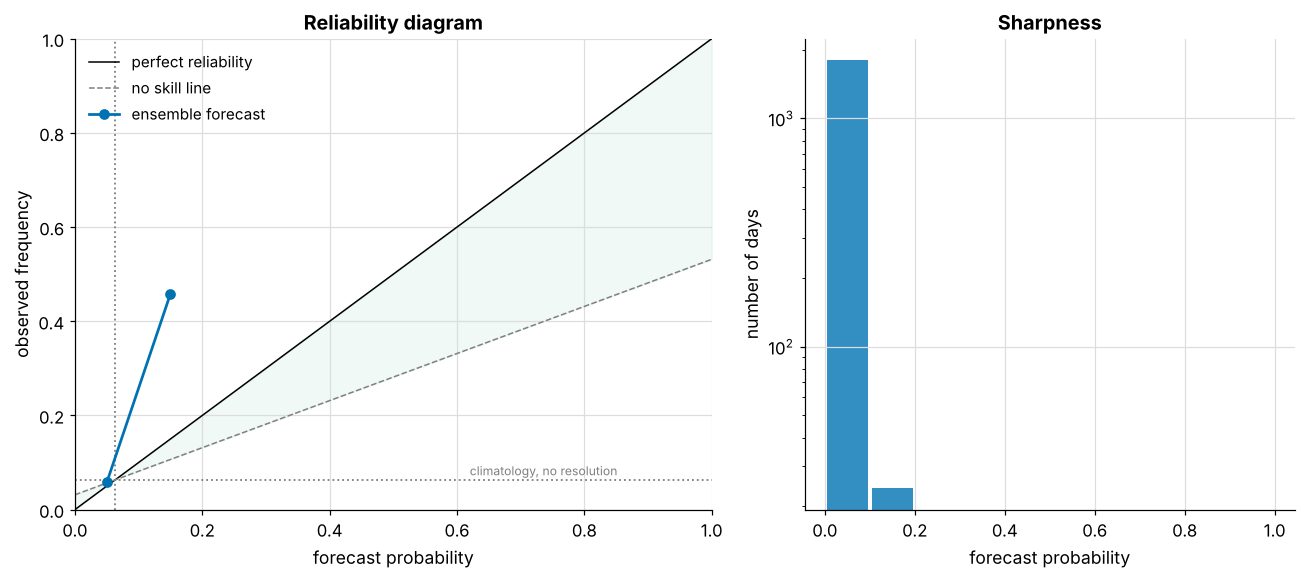

In [7]:
fig, (ax, axh) = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})

# Reference lines.
ax.plot([0, 1], [0, 1], "k-", lw=1, label="perfect reliability")
ax.axhline(climatology, color="grey", ls=":", lw=1.2); ax.axvline(climatology, color="grey", ls=":", lw=1.2)
ax.text(0.62, climatology + 0.01, "climatology, no resolution", color="grey", fontsize=8)
xs = np.array([0, 1]); noskill = climatology + 0.5 * (xs - climatology)
ax.plot(xs, noskill, color="grey", ls="--", lw=1, label="no skill line")
ax.fill_between(xs, noskill, xs, color=PALETTE["accent"], alpha=0.06)

# The forecast.
ax.plot(centres, obs_freq, "-o", color=PALETTE["control"], ms=6, lw=1.8, label="ensemble forecast")
ax.set_xlabel("forecast probability"); ax.set_ylabel("observed frequency")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_title("Reliability diagram"); ax.legend(loc="upper left")

# Sharpness, how often each probability is issued (log scale, the zero bin dominates).
axh.bar(centres, counts, width=0.09, color=PALETTE["control"], alpha=0.8)
axh.set_yscale("log"); axh.set_xlabel("forecast probability"); axh.set_ylabel("number of days")
axh.set_title("Sharpness")
plt.tight_layout(); plt.show()

## 4. The rank histogram

Does the observation behave like one more member of the ensemble? For each day, count how many members fall below the observation. If the ensemble is reliable, the observation is equally likely to land in any of the $N + 1$ gaps, and the histogram is flat.

- U shape, the ensemble is too narrow, the truth often falls outside it.
- Dome shape, the ensemble is too wide.
- Sloped, the members are biased low or high.

Ties, for example many members and the observation at zero flow, are broken at random so that flat really means flat.

In [8]:
def rank_histogram(ensemble, obs, seed=0):
    """Rank of the observation among the sorted members, ties broken at random. Returns Nens + 1 counts."""
    rng = np.random.default_rng(seed)
    Nens, n = ensemble.shape
    counts = np.zeros(Nens + 1, dtype=int)
    for t in range(n):
        members = ensemble[:, t]
        below = np.sum(members < obs[t])               # members strictly below the observation
        equal = np.sum(members == obs[t])              # ties
        rank = below + (rng.integers(0, equal + 1) if equal > 0 else 0)
        counts[rank] += 1
    return counts

rh = rank_histogram(ensemble, Qobs, seed=1)
expected = len(Qobs) / (Nens + 1)                      # the flat reference height

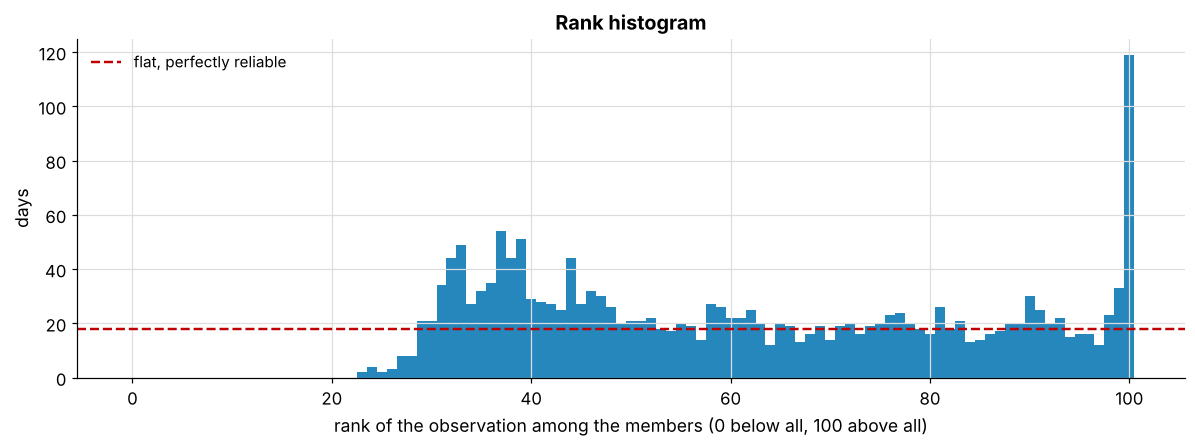

observation above every member on 119 days, below every member on 0 days, flat would be 18


In [9]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(np.arange(Nens + 1), rh, width=1.0, color=PALETTE["control"], alpha=0.85)
ax.axhline(expected, color=PALETTE["threshold"], ls="--", lw=1.6, label="flat, perfectly reliable")
ax.set_xlabel("rank of the observation among the members (0 below all, 100 above all)")
ax.set_ylabel("days"); ax.set_title("Rank histogram")
ax.legend(); plt.tight_layout(); plt.show()

print(f"observation above every member on {rh[-1]} days, below every member on {rh[0]} days, flat would be {expected:.0f}")

The pile at the top says that the observation is often above all members. The ensemble runs too dry, which is what a rainfall multiplier that averages 0.6 produces.

## 5. The CRPS

The continuous ranked probability score generalises the mean absolute error to a whole predictive distribution. With forecast cumulative distribution $F$ and observation $y$,

$$ \mathrm{CRPS}(F, y) = \int_{-\infty}^{\infty}\left(F(x) - \mathbf{1}[x \ge y]\right)^2 dx . $$

It rewards forecasts that are sharp and right, it has the units of the variable (mm per day), and for a single deterministic value it reduces to the absolute error. For an ensemble there is an exact closed form (Hersbach 2000),

$$ \mathrm{CRPS} = \frac{1}{m}\sum_i |x_i - y| - \frac{1}{2m^2}\sum_i\sum_j |x_i - x_j| . $$

We implement it two ways and check that they agree.

In [10]:
def crps_ensemble(members, y):
    """Exact CRPS of one ensemble forecast for one observation, closed form."""
    x = np.sort(np.asarray(members, float)); m = len(x)
    mae_term = np.mean(np.abs(x - y))                       # mean absolute distance to the observation
    i = np.arange(1, m + 1)
    spread_term = 2.0 * np.sum((2 * i - m - 1) * x) / (2.0 * m * m)   # mean distance between members, halved
    return mae_term - spread_term

def crps_integral(members, y):
    """CRPS by direct integration of the squared difference between the step CDF and the observation step."""
    x = np.sort(np.asarray(members, float)); m = len(x)
    pts = np.unique(np.concatenate([x, [y]]))               # breakpoints of both step functions
    total = 0.0
    for a, b in zip(pts[:-1], pts[1:]):
        xmid = 0.5 * (a + b)
        F = np.mean(x <= xmid)                              # empirical CDF on the segment
        H = 1.0 if xmid >= y else 0.0                       # the observation step
        total += (F - H) ** 2 * (b - a)
    return total

# Check on a handful of days. The two must agree to machine precision.
check = max(abs(crps_ensemble(ensemble[:, t], Qobs[t]) - crps_integral(ensemble[:, t], Qobs[t]))
            for t in range(0, N_EVAL, 200))
print(f"largest difference between the two implementations {check:.2e} mm/day")

largest difference between the two implementations 8.88e-16 mm/day


In [11]:
# CRPS on every day, and its mean. For comparison, the absolute error of the control run.
crps_t = np.array([crps_ensemble(ensemble[:, t], Qobs[t]) for t in range(N_EVAL)])
mean_crps = crps_t.mean()
control_mae = np.mean(np.abs(Qctrl - Qobs))
print(f"mean CRPS of the ensemble {mean_crps:.3f} mm/day")
print(f"mean absolute error of the control run {control_mae:.3f} mm/day")

mean CRPS of the ensemble 0.965 mm/day
mean absolute error of the control run 0.747 mm/day


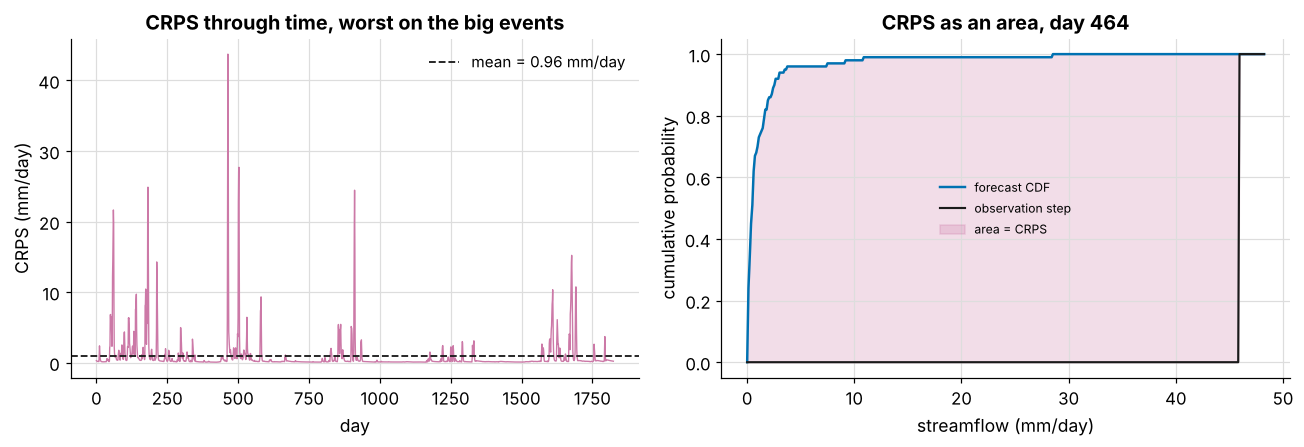

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# CRPS through time.
axes[0].plot(crps_t, color=PALETTE["accent2"], lw=0.9)
axes[0].axhline(mean_crps, color=PALETTE["obs"], ls="--", lw=1.2, label=f"mean = {mean_crps:.2f} mm/day")
axes[0].set_xlabel("day"); axes[0].set_ylabel("CRPS (mm/day)")
axes[0].set_title("CRPS through time, worst on the big events"); axes[0].legend()

# One day, the area between the two step functions is the CRPS.
day = int(np.argmax(crps_t))
x = np.sort(ensemble[:, day]); y = Qobs[day]
grid = np.linspace(0, max(x.max(), y) * 1.05, 400)
F = np.searchsorted(x, grid, side="right") / len(x)
H = (grid >= y).astype(float)
axes[1].plot(grid, F, color=PALETTE["control"], label="forecast CDF")
axes[1].plot(grid, H, color=PALETTE["obs"], lw=1.4, label="observation step")
axes[1].fill_between(grid, F, H, color=PALETTE["accent2"], alpha=0.25, label="area = CRPS")
axes[1].set_xlabel("streamflow (mm/day)"); axes[1].set_ylabel("cumulative probability")
axes[1].set_title(f"CRPS as an area, day {day}"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Act on the diagnosis

Verification is not a report card, it is a diagnosis. The scores all point the same way. The raw ensemble can separate event days from quiet days (ROC area about 0.7 in Notebook 3), but it is badly calibrated. It over forecasts probabilities, it is too narrow, and it runs dry because its rainfall multiplier averages 0.6.

The cure is not a new model. It is post processing. Two changes.

1. Centre the rainfall multiplier at 1.0 with a modest spread.
2. Sample the parameters around the calibrated control instead of across their full ranges.

In [13]:
def generate_calibrated_ensemble(seed=7, Nens=100):
    """A better behaved ensemble. Rainfall centred at 1.0, parameters around the control values."""
    rng = np.random.default_rng(seed)
    cp = h.CONTROL_PARS
    ens = np.zeros((Nens, N_EVAL))
    for i in range(Nens):
        mult = max(0.05, rng.normal(1.0, 0.18))              # rainfall centred on the observed depth
        pars = {"Huz": float(np.clip(cp["Huz"] * rng.uniform(0.6, 1.4), 5, 500)),
                "B": float(np.clip(cp["B"] * rng.uniform(0.6, 1.4), 0.05, 2)),
                "Alp": float(np.clip(cp["Alp"] * rng.uniform(0.7, 1.3), 0.02, 0.98)),
                "Nq": cp["Nq"],
                "Kq": float(np.clip(cp["Kq"] * rng.uniform(0.6, 1.4), 0.05, 0.98)),
                "Ks": float(np.clip(cp["Ks"] * rng.uniform(0.5, 1.5), 0.0005, 0.2))}
        ens[i] = h.hymod01(PP[:N_EVAL] * mult, PET[:N_EVAL], pars)["Q"]
    return ens

ens_cal = generate_calibrated_ensemble(seed=7)
prob_cal = (ens_cal >= flood_th).mean(axis=0)

In [14]:
# Re-verify. Brier, skill score, reliability curve and mean CRPS of the calibrated ensemble.
BS_cal = np.mean((prob_cal - obs_events) ** 2)
BSS_cal = 1 - BS_cal / BS_clim
cen_cal, of_cal, _ = reliability_curve(prob_cal, obs_events)
crps_cal = np.mean([crps_ensemble(ens_cal[:, t], Qobs[t]) for t in range(N_EVAL)])
rh_cal = rank_histogram(ens_cal, Qobs, seed=1)

print(f"{'':14s}{'raw':>10s}{'calibrated':>12s}")
print(f"{'Brier score':14s}{BS:10.4f}{BS_cal:12.4f}")
print(f"{'BSS':14s}{BSS:10.3f}{BSS_cal:12.3f}")
print(f"{'mean CRPS':14s}{mean_crps:10.3f}{crps_cal:12.3f}   control run MAE {control_mae:.3f}")

                     raw  calibrated
Brier score       0.0595      0.0283
BSS               -0.008       0.521
mean CRPS          0.965       0.495   control run MAE 0.747


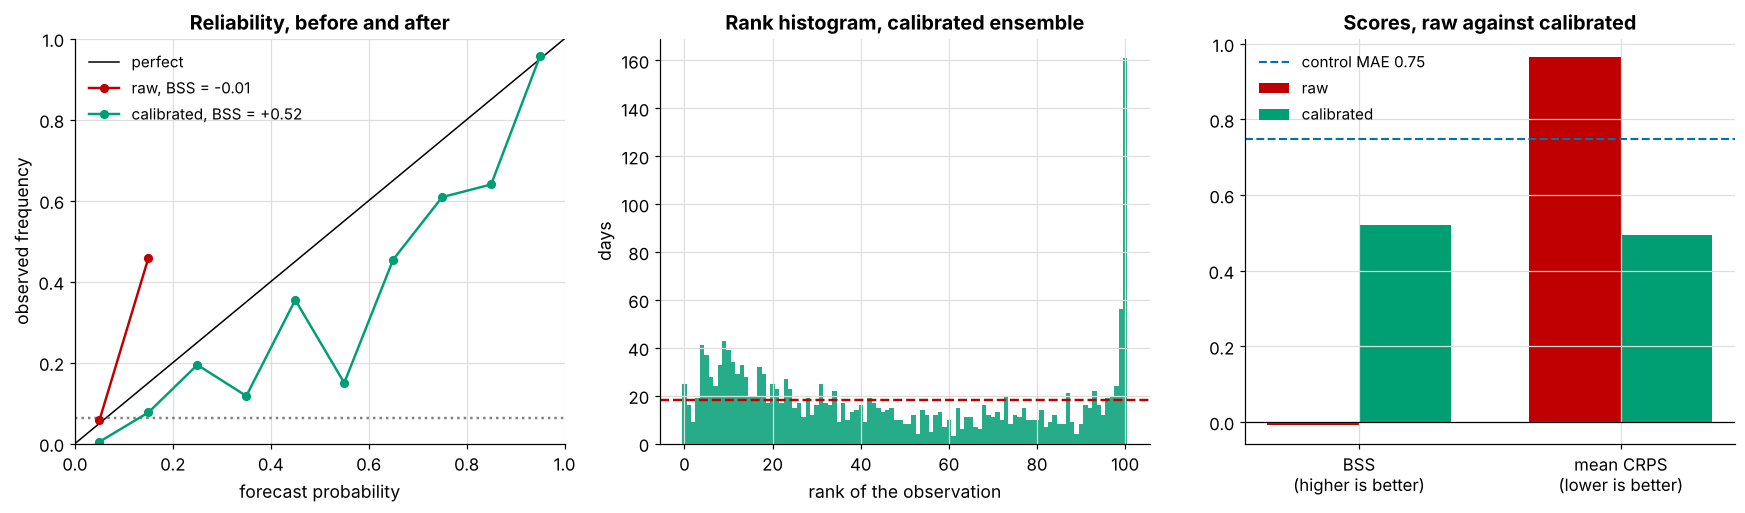

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Reliability, raw against calibrated.
axes[0].plot([0, 1], [0, 1], "k-", lw=1, label="perfect")
axes[0].axhline(climatology, color="grey", ls=":")
axes[0].plot(centres, obs_freq, "-o", color=PALETTE["threshold"], ms=5, label=f"raw, BSS = {BSS:+.2f}")
axes[0].plot(cen_cal, of_cal, "-o", color=PALETTE["accent"], ms=5, label=f"calibrated, BSS = {BSS_cal:+.2f}")
axes[0].set_xlabel("forecast probability"); axes[0].set_ylabel("observed frequency")
axes[0].set_title("Reliability, before and after"); axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1)
axes[0].legend(loc="upper left")

# Rank histogram of the calibrated ensemble.
axes[1].bar(np.arange(Nens + 1), rh_cal, width=1.0, color=PALETTE["accent"], alpha=0.85)
axes[1].axhline(expected, color=PALETTE["threshold"], ls="--", lw=1.6)
axes[1].set_xlabel("rank of the observation"); axes[1].set_ylabel("days")
axes[1].set_title("Rank histogram, calibrated ensemble")

# Scores side by side.
labels = ["BSS\n(higher is better)", "mean CRPS\n(lower is better)"]
xpos = np.arange(2); w = 0.35
axes[2].bar(xpos - w / 2, [BSS, mean_crps], w, color=PALETTE["threshold"], label="raw")
axes[2].bar(xpos + w / 2, [BSS_cal, crps_cal], w, color=PALETTE["accent"], label="calibrated")
axes[2].axhline(control_mae, color=PALETTE["control"], ls="--", lw=1.4, label=f"control MAE {control_mae:.2f}")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_xticks(xpos); axes[2].set_xticklabels(labels)
axes[2].set_title("Scores, raw against calibrated"); axes[2].legend()
plt.tight_layout(); plt.show()

The calibrated ensemble is reliable, its rank histogram is close to flat, and its CRPS drops below the absolute error of the single control run. The ensemble now adds value over the best deterministic forecast.

## 7. Your turn

A deterministic forecast is a probability forecast that only says 0 or 1. Score the control run that way and compare it with the two ensembles.

In [16]:
#################### Your Code Goes Here #########################
# Step 1. The control run as a probability. 1 on days when Qctrl is at or above the threshold, else 0.
prob_ctrl = (Qctrl >= flood_th).astype(float)

# Step 2. Its Brier score and Brier skill score (same formulas as section 2).
BS_ctrl = np.mean((prob_ctrl - obs_events) ** 2)
BSS_ctrl = 1 - BS_ctrl / BS_clim

# Step 3. Print the three Brier skill scores side by side, control, raw ensemble, calibrated ensemble.
print(f"BSS control {BSS_ctrl:+.3f}   raw ensemble {BSS:+.3f}   calibrated ensemble {BSS_cal:+.3f}")
###################################################################

BSS control +0.165   raw ensemble -0.008   calibrated ensemble +0.521


Questions for the group

1. The control run scored better than the raw ensemble on the Brier score. Does that make it the better forecast? Which other score disagrees?
2. In Module 2 the EF5 run for the June 2024 flood was a single deterministic simulation. Which of today's tools apply to it, and which need an ensemble?

## Recap

- The Brier score and its skill score compare a probability forecast with climatology.
- The reliability diagram and the rank histogram say what is wrong, over forecasting, too narrow, biased.
- The CRPS scores the whole distribution in the units of the variable, and reduces to the absolute error for a single value.
- No single score told the whole story. Together they gave a diagnosis, and acting on it turned a useless probability into a useful one.

## References and credits

- Brier, G. W., 1950. Verification of forecasts expressed in terms of probability. Monthly Weather Review, 78, 1 to 3.
- Murphy, A. H., 1973. A new vector partition of the probability score. Journal of Applied Meteorology, 12, 595 to 600.
- Hamill, T. M., 2001. Interpretation of rank histograms for verifying ensemble forecasts. Monthly Weather Review, 129, 550 to 560.
- Hersbach, H., 2000. Decomposition of the continuous ranked probability score for ensemble prediction systems. Weather and Forecasting, 15, 559 to 570.
- Wilks, D. S., 2019. Statistical Methods in the Atmospheric Sciences, 4th edition, Elsevier. Chapter 9.
- Adapted from the Ensemble Forecast Evaluation series prepared by Humberto Vergara and Mohamed Abdelkader for the CIROH Summer Institute 2026.